In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('dark_background')
sns.set_palette('viridis')
df = pd.read_csv(r"C:\Users\eldep\Downloads\COUNT_2026-10-19-0225 (1).csv")
df['PERIOD'] = pd.to_datetime(df['PERIOD'])
df = df.sort_values('PERIOD')
df['VALUE'] = pd.to_numeric(df['VALUE'], errors='coerce')
df = df.dropna(subset=['VALUE'])

In [2]:
summary = df.groupby('SERIES_DESCRIPTION')['VALUE'].agg(
    Count='count',
    Mean='mean',
    Median='median',
    Min='min',
    Max='max',
    Std='std'
).reset_index()
print(summary)

                                  SERIES_DESCRIPTION  Count      Mean  Median  \
0  Henry Hub Natural Gas Spot Price (Dollars per ...   7480  4.068651   3.340   
1  Natural Gas Futures Contract 1 (Dollars per Mi...   7593  4.008141   3.250   
2  Natural Gas Futures Contract 2 (Dollars per Mi...   7597  4.090807   3.305   
3  Natural Gas Futures Contract 3 (Dollars per Mi...   7589  4.156829   3.354   
4  Natural Gas Futures Contract 4 (Dollars per Mi...   7603  4.188734   3.397   

     Min     Max       Std  
0  1.050  30.720  2.172632  
1  1.323  15.378  2.201108  
2  1.374  15.427  2.242470  
3  1.423  15.287  2.275809  
4  1.468  14.906  2.276152  


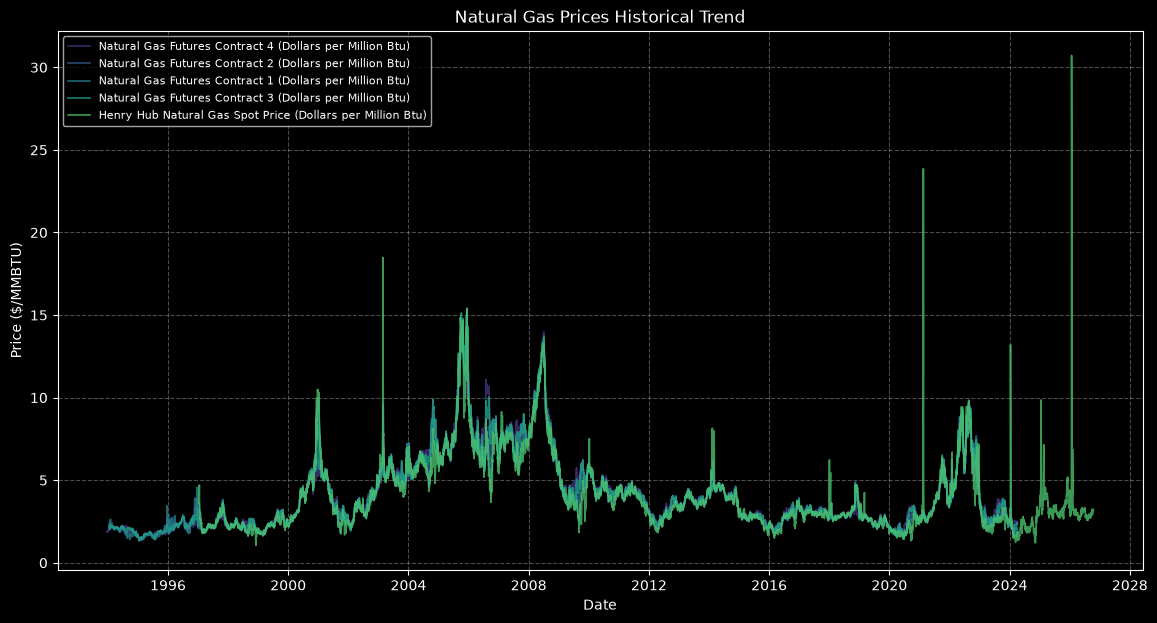

In [3]:
plt.figure(figsize=(14, 7))
for series in df['SERIES_DESCRIPTION'].unique():
    subset = df[df['SERIES_DESCRIPTION'] == series]
    plt.plot(subset['PERIOD'], subset['VALUE'], label=series, alpha=0.8, linewidth=1.2)
plt.title('Natural Gas Prices Historical Trend')
plt.xlabel('Date')
plt.ylabel('Price ($/MMBTU)')
plt.legend(loc='upper left', fontsize=8)
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

<Figure size 1400x600 with 0 Axes>

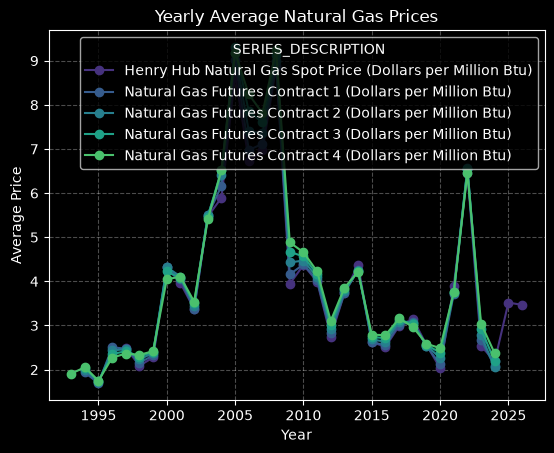

In [4]:
df['YEAR'] = df['PERIOD'].dt.year
yearly_avg = df.groupby(['YEAR', 'SERIES_DESCRIPTION'])['VALUE'].mean().unstack()
plt.figure(figsize=(14, 6))
yearly_avg.plot(kind='line', marker='o', linewidth=1.5)
plt.title('Yearly Average Natural Gas Prices')
plt.xlabel('Year')
plt.ylabel('Average Price')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

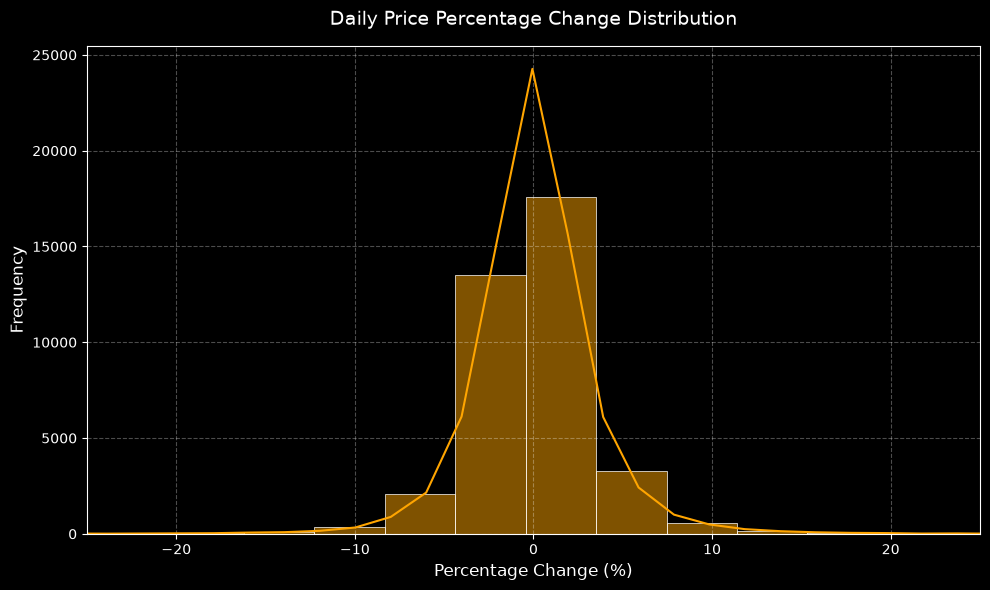

In [5]:
df_sorted = df.sort_values(['SERIES_DESCRIPTION', 'PERIOD']).copy()
df_sorted['DAILY_CHANGE_PCT'] = df_sorted.groupby('SERIES_DESCRIPTION')['VALUE'].pct_change() * 100

plt.figure(figsize=(10, 6))
sns.histplot(df_sorted['DAILY_CHANGE_PCT'].dropna(), bins=100, kde=True, color='orange')
plt.xlim(-25, 25)
plt.title('Daily Price Percentage Change Distribution', fontsize=14, pad=15)
plt.xlabel('Percentage Change (%)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

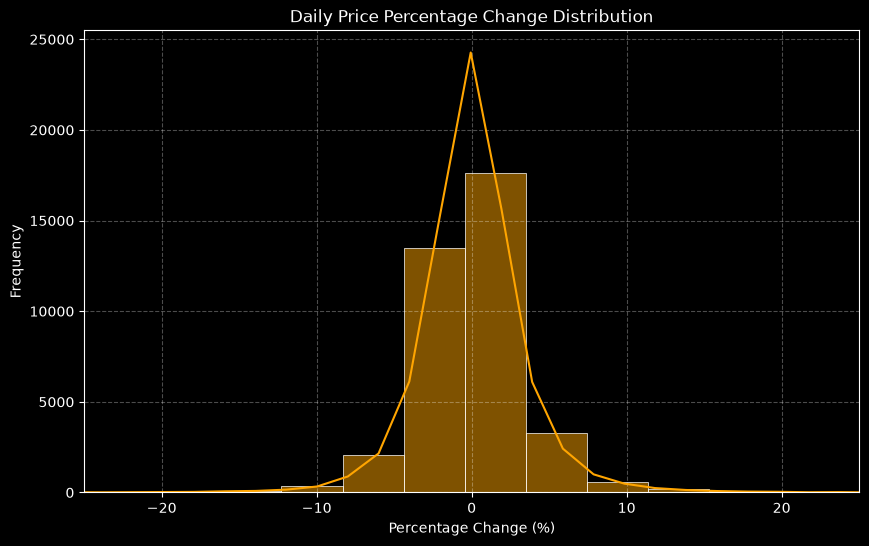

In [6]:
df['DAILY_CHANGE_PCT'] = df.groupby('SERIES_DESCRIPTION')['VALUE'].pct_change() * 100
plt.figure(figsize=(10, 6))
sns.histplot(df['DAILY_CHANGE_PCT'].dropna(), bins=100, kde=True, color='orange')
plt.xlim(-25, 25)
plt.title('Daily Price Percentage Change Distribution')
plt.xlabel('Percentage Change (%)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

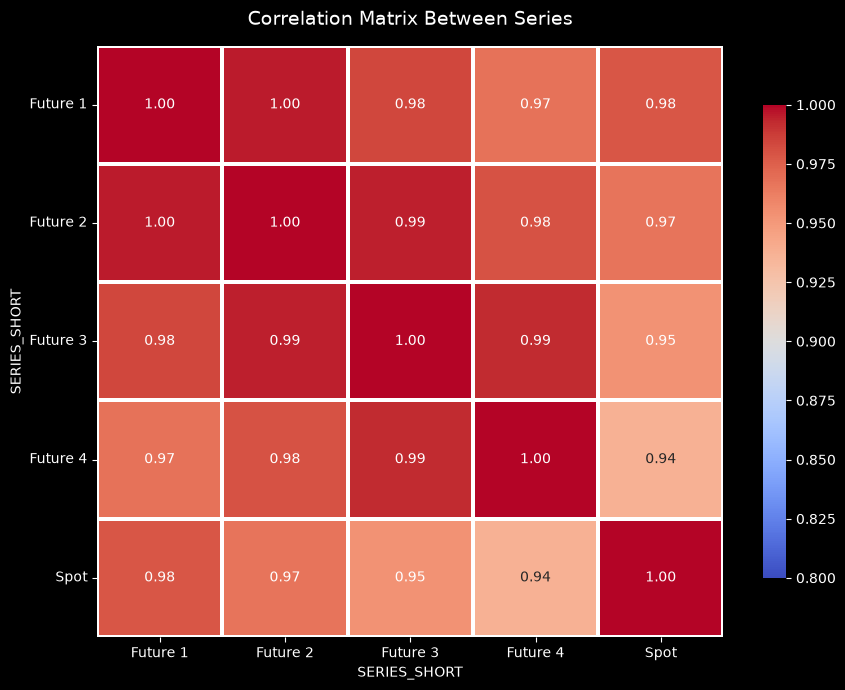

In [7]:
short_names = {
    'Henry Hub Natural Gas Spot Price (Dollars per Million Btu)': 'Spot',
    'Natural Gas Futures Contract 1 (Dollars per Million Btu)': 'Future 1',
    'Natural Gas Futures Contract 2 (Dollars per Million Btu)': 'Future 2',
    'Natural Gas Futures Contract 3 (Dollars per Million Btu)': 'Future 3',
    'Natural Gas Futures Contract 4 (Dollars per Million Btu)': 'Future 4'
}

df_clean = df.copy()
df_clean['SERIES_SHORT'] = df_clean['SERIES_DESCRIPTION'].map(short_names).fillna(df_clean['SERIES_DESCRIPTION'])
df_clean = df_clean.drop_duplicates(subset=['PERIOD', 'SERIES_SHORT'])

pivot_corr = df_clean.pivot_table(index='PERIOD', columns='SERIES_SHORT', values='VALUE', aggfunc='mean').corr()

plt.figure(figsize=(9, 7))
sns.heatmap(pivot_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=0.8, vmax=1, linewidths=1.5, cbar_kws={'shrink': 0.8})
plt.title('Correlation Matrix Between Series', fontsize=14, pad=15)
plt.xticks(rotation=0, ha='center', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()